# 2 · One network for a family of airfoils

$\psi(x, y; m, p, t, \alpha)$ for every NACA 4-digit section with $m \le 0.06$,
$0.3 \le p \le 0.5$, $0.08 \le t \le 0.18$ and $-4° \le \alpha \le 8°$. The network sees
inverse-Joukowski coordinates; the lift is measured from the predicted field. See
[Lesson 2](../docs/lessons/02-airfoil-flow-fields.md) and
[docs/pinn_airfoil_flowfield.md](../docs/pinn_airfoil_flowfield.md).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from pinncfd import io, plotting as P

torch.set_num_threads(1)  # one thread: reductions in a fixed order, reproducible outputs
P.use_style()
DEG = np.pi / 180
ROOT = Path("..").resolve()
RESULTS = ROOT / "validation" / "results"
CK = RESULTS / "checkpoints"
DEVICE = "cpu"
from pinncfd.external.geometry import naca, panel_solution
from pinncfd.pinn_airfoil_flowfield import AirfoilPINN, build_reference, family
from pinncfd.pinn_airfoil_flowfield.problem import evaluate, lift_from_circulation, predict_velocity

model, _ = io.load_checkpoint(CK / "phase2_physics_data.pt", AirfoilPINN, DEVICE)

Held-out test sections, against a 400-panel AERO-01 solution:

In [2]:
cases = [family._naca(code, a) for code, a in (("0012", 4.0), ("2412", 4.0), ("4415", 7.0))]
ref = build_reference(cases, n_field=256)
s = evaluate(model, ref, DEVICE, per_case=True)
for i, c in enumerate(cases):
    print(f"{c.name:20s} velocity error {s['error'][i]:.4f}  cl panel {s['cl_ref'][i]:.3f}  "
          f"PINN (circulation) {s['cl_circulation'][i]:.3f}  (pressure) {s['cl_pressure'][i]:.3f}")

NACA 0012 α=+4.0°    velocity error 0.0101  cl panel 0.483  PINN (circulation) 0.399  (pressure) 0.479
NACA 2412 α=+4.0°    velocity error 0.0058  cl panel 0.742  PINN (circulation) 0.627  (pressure) 0.755
NACA 4415 α=+7.0°    velocity error 0.0097  cl panel 1.395  PINN (circulation) 1.194  (pressure) 1.325


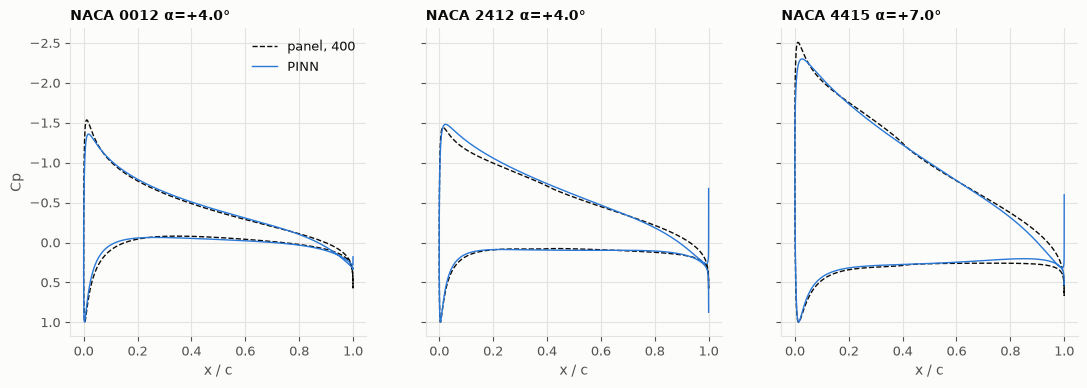

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
xs = ref.surf_xy[:, 0].reshape(len(cases), -1)
cp_ref = ref.surf_cp.reshape(len(cases), -1)
for ax, i in zip(axes, range(len(cases))):
    ax.plot(xs[i], cp_ref[i], "--", color=P.REFERENCE, lw=1, label="panel, 400")
    ax.plot(xs[i], s["cp"][i], color=P.SERIES[0], lw=1, label="PINN")
    ax.set_title(cases[i].name, fontsize=10); ax.set_xlabel("x / c")
axes[0].invert_yaxis(); axes[0].set_ylabel("Cp"); axes[0].legend();

The speed field around a cambered section, predicted for a shape and incidence the network never saw with data:

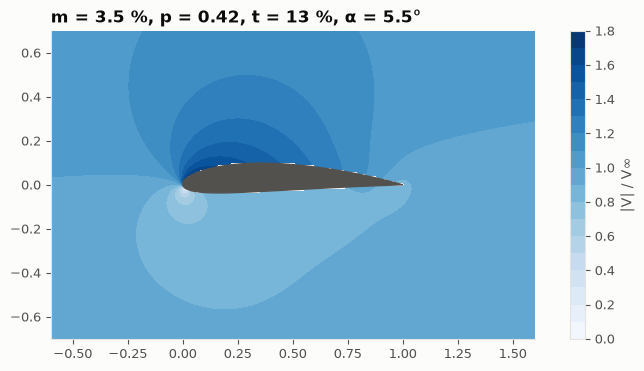

In [4]:
from pinncfd.external.geometry import inside
m, p, t, a = 0.035, 0.42, 0.13, 5.5 * DEG
X, Y = np.meshgrid(np.linspace(-0.6, 1.6, 221), np.linspace(-0.7, 0.7, 141))
xy = np.column_stack([X.ravel(), Y.ravel()])
u, v = predict_velocity(model, xy, np.tile([m, p, t, a], (len(xy), 1)), DEVICE)
speed = np.where(inside(m, p, t, xy), np.nan, np.hypot(u, v)).reshape(X.shape)
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.contourf(X, Y, speed, levels=np.linspace(0, 1.8, 19), cmap="Blues")
ax.fill(*naca(m, p, t).coordinates(200).T, color=P.TEXT_MUTED)
ax.set_aspect("equal"); ax.grid(False); fig.colorbar(im, label="|V| / V∞")
ax.set_title("m = 3.5 %, p = 0.42, t = 13 %, α = 5.5°");

Lift curves of three sections, PINN against the panel method:

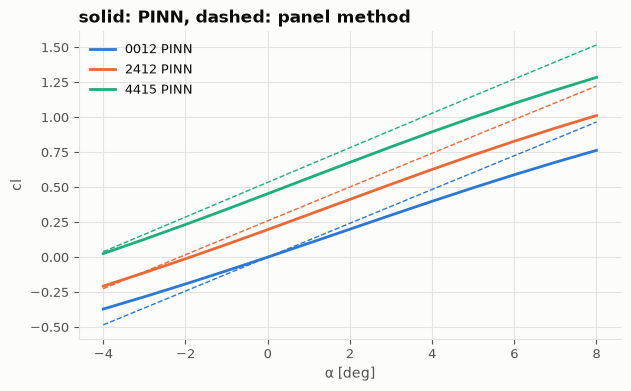

In [5]:
alphas = np.linspace(-4, 8, 13)
fig, ax = plt.subplots(figsize=(7, 4))
for i, code in enumerate(("0012", "2412", "4415")):
    q = np.array([family._naca(code, al).params for al in alphas])
    ax.plot(alphas, lift_from_circulation(model, q, DEVICE), color=P.SERIES[i], label=f"{code} PINN")
    ax.plot(alphas, [panel_solution(*r[:3], r[3], 200).cl for r in q], "--", color=P.SERIES[i], lw=1)
ax.set_xlabel("α [deg]"); ax.set_ylabel("cl"); ax.set_title("solid: PINN, dashed: panel method"); ax.legend();